# 06. LSOA distances and spatial-autocorrelation experiment

This London experiment adapts the neighbouring-location idea from [Kallberg and Shimizu](https://doi.org/10.1007/s11146-024-09997-w), without claiming to reproduce their transaction-level spatial-price IV model. Our units are LSOAs. Representative coordinates are averages of distinct observed sale-location points, **not official polygon centroids**, and may favour streets with transactions. Official population-weighted centroids would improve this.

Outputs: LSOA coordinates, kilometre-distance neighbour links, sparse spatial weights, network maps, global Moran statistics, raw/residual maps and spatially lagged crime (SLX) regressions. A spatial lag of crime is different from a spatial lag of prices. We do not put contemporaneous neighbouring prices into ordinary OLS: that would create a simultaneous spatial-price problem. The SLX model remains associational and is not a causal spatial spillover estimate.


In [1]:
from pathlib import Path
try:
    from google.colab import drive
except ImportError:
    ROOT=Path.cwd()
else:
    drive.mount('/content/drive')
    ROOT=Path('/content/drive/MyDrive/HE3027 Project')
DATA_DIR=ROOT/'data'
MERGED=DATA_DIR/'crime_housing_merged.csv.gz'
if not MERGED.is_file():raise FileNotFoundError('Run the data-audit notebook first.')

OUT=DATA_DIR/'06_crime_spatial_outputs';OUT.mkdir(exist_ok=True)
SEED=302706
NEIGHBOUR_COUNTS=[4,8,12]
PERMUTATIONS=199
YEARS=[2012,2013,2014,2015]


In [2]:
import hashlib
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
CRIMES = ['allcrime', 'violent_crime', 'propertycrime']
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 4)

def table(data, filename):
    """Save the complete table and display a compact preview."""
    data.to_csv(OUT / (filename + '.csv'))
    display(data.head(20) if len(data) > 20 else data)
    if len(data) > 20:
        print(f'Showing 20 of {len(data)} rows; the complete table is saved as {filename}.csv.')

VARIABLE_LABELS = {
    'detached_dum': 'Detached (relative to flat)',
    'semi_d_dum': 'Semi-detached (relative to flat)',
    'terrace_dum': 'Terraced (relative to flat)',
    'freehold': 'Freehold',
    'newbuild': 'New build',
    'tube_distnear_km': 'Distance to tube station (km)',
    'bus_distnear_km': 'Distance to bus stop (km)',
    'thamesriv_dist_km': 'Distance to Thames (km)',
    'Nearest_Park_dist_km': 'Distance to park (km)',
    'dist_to_cbd': 'Distance to CBD (km)',
    'Bus_stopscount_200m': 'Bus stops within 200m',
    'heritage_count_200m': 'Heritage buildings within 200m',
    'percent_noedu': 'Residents without qualifications',
    'percent_minorities': 'Minority residents',
    'lone_hh': 'Lone-parent households',
    'lnpay': 'Log borough annual pay',
    'jobdensity': 'Borough job density',
    'hoursworked': 'Borough weekly hours worked',
    'unemployment': 'Borough unemployment',
}

def coefficient_inference(coefficients, results):
    """Compute inference for every coefficient from its saved clustered SE."""
    keys = [name for name in ['panel', 'model', 'crime', 'measure', 'timing']
            if name in coefficients and name in results]
    metadata = results[keys + ['clusters']]
    enriched = coefficients.drop(columns=['clusters', 't', 'p', 'ci_low', 'ci_high'], errors='ignore')
    enriched = enriched.merge(metadata, on=keys, how='left', validate='many_to_one')
    if enriched.clusters.isna().any():
        raise ValueError('Coefficient rows could not be matched to regression metadata.')
    degrees_freedom = enriched.clusters - 1
    enriched['t'] = enriched.beta / enriched.se
    enriched['p'] = 2 * stats.t.sf(np.abs(enriched.t), degrees_freedom)
    critical = stats.t.ppf(0.975, degrees_freedom)
    enriched['ci_low'] = enriched.beta - critical * enriched.se
    enriched['ci_high'] = enriched.beta + critical * enriched.se
    return enriched

def show_models(results, filename, coefficient_filename):
    """Show one expandable table per model with crime AND control coefficients."""
    from html import escape
    from IPython.display import HTML

    results.to_csv(OUT / (filename + '.csv'), index=False)
    coefficients = coefficient_inference(pd.read_csv(OUT / coefficient_filename), results)
    coefficients.to_csv(OUT / coefficient_filename, index=False)
    cards = []

    def number(value):
        if pd.isna(value):
            return '—'
        if value != 0 and abs(value) < 0.0001:
            return f'{value:.2e}'
        return f'{value:.4f}'

    for _, regression in results.iterrows():
        selected = coefficients.model.eq(regression['model'])
        for key in ['panel', 'crime', 'measure', 'timing']:
            if key in coefficients and key in results:
                selected &= coefficients[key].eq(regression[key])
        rows = coefficients.loc[selected].copy()
        title = regression['model'] + ' · ' + str(regression.get('crime', regression.get('measure', '')))
        if 'timing' in results:
            title += ' · ' + regression['timing']
        rendered = []
        for _, row in rows.iterrows():
            label = VARIABLE_LABELS.get(row.variable, row.variable)
            if row.variable.startswith('log1p_'):
                label = 'Crime: log(1 + ' + row.variable[6:].replace('_', ' ') + ')'
            rendered.append({
                'Variable': label,
                'Coefficient': number(row.beta),
                'Clustered SE': number(row.se),
                't statistic': f'{row.t:.2f}',
                '95% CI': number(row.ci_low) + ' to ' + number(row.ci_high),
                'p-value': '<0.001' if row.p < 0.001 else f'{row.p:.3f}',
            })
        effects = regression.get('fixed_effects', '')
        effects = 'None' if pd.isna(effects) or not effects else str(effects)
        r2_label = 'Within R²' if regression.r2_type == 'within' else 'R²'
        subtitle = (f'N = {int(regression.N):,} | LSOA clusters = {int(regression.clusters):,}'
                    f' | {r2_label} = {regression.r2:.4f}')
        body = pd.DataFrame(rendered).to_html(index=False, border=0, escape=True)
        omitted = regression.get('absorbed_or_collinear', '')
        note = '' if pd.isna(omitted) or not omitted else '<p>Absorbed/collinear: ' + escape(str(omitted)) + '</p>'
        cards.append('<details class="reg-card"><summary>' + escape(title) + '</summary>'
                     '<p>' + escape(subtitle) + '</p><p>Fixed effects: ' + escape(effects) + '</p>'
                     + body + note + '</details>')
    style = '<style>.reg-card{margin:10px 0;padding:12px;border:1px solid #bbb;border-radius:6px;overflow-x:auto}.reg-card summary{cursor:pointer;font-weight:600}.reg-card table{border-collapse:collapse;width:100%;max-width:950px}.reg-card th,.reg-card td{padding:7px 10px;border-bottom:1px solid #ddd;text-align:right;white-space:nowrap}.reg-card th:first-child,.reg-card td:first-child{text-align:left}.reg-card p{font-size:13px}</style>'
    display(HTML(style + '<p>Expand a regression to view all estimated coefficients. Standard errors are clustered by LSOA.</p>' + ''.join(cards)))
    return coefficients


In [3]:
df=pd.read_csv(MERGED,low_memory=False)
assert df.transaction_id.is_unique


In [4]:
LOCATION_MODE = 'continuous'
RIVER_THRESHOLD_METRES = None

data = df.copy()
data['lnprice'] = np.log(data.price.where(data.price.gt(0)))
data['newbuild'] = data.age.eq('Y').astype(float)
data['grossannualpay_k'] = data.grossannualpay / 1000
PROPERTY = ['detached_dum','semi_d_dum','terrace_dum','freehold','newbuild']
ECONOMIC = ['grossannualpay_k','jobdensity','hoursworked','unemployment']
if LOCATION_MODE == 'continuous':
    LOCATION = []
    for name in ['tube_distnear','bus_distnear','thamesriv_dist']:
        data[name+'_km'] = data[name]/1000
        LOCATION.append(name+'_km')
elif LOCATION_MODE == 'indicators':
    if RIVER_THRESHOLD_METRES is None or RIVER_THRESHOLD_METRES <= 0:
        raise ValueError('Specify a positive river proximity threshold in metres.')
    thresholds = {'tube_distnear':200, 'bus_distnear':200, 'thamesriv_dist':RIVER_THRESHOLD_METRES}
    LOCATION = ['tube_near','bus_near','river_near']
    for name, target in zip(thresholds,LOCATION):
        data[target] = data[name].le(thresholds[name]).astype(float).where(data[name].notna())
else:
    raise ValueError('LOCATION_MODE must be continuous or indicators.')
VARIABLE_LABELS.update({'grossannualpay_k':'Borough annual pay (GBP 1,000)',
                        'tube_near':'Tube station within 200m', 'bus_near':'Bus stop within 200m',
                        'river_near':'River within specified threshold'})


In [5]:
MAIN=['mps_all','mps_violence','mps_property']
CRIME_NAMES=dict(zip(MAIN,['All crime','Violence','Property crime']))
CONTROLS=PROPERTY+LOCATION+[c for c in ECONOMIC if c!='jobdensity']
for c in MAIN:data['log1p_'+c]=np.log1p(data[c+'_prior12'])
required=['lnprice','lsoacode','msoa11','oslaua','yearquarter','year','lat','lon']+CONTROLS+['log1p_'+c for c in MAIN]
valid=data[required].replace('',np.nan).notna().all(axis=1)
valid &= np.isfinite(data[required].select_dtypes(include='number')).all(axis=1)
valid &= data.analysis_geography_ok & data.mps_exposures_available & data.mps_geography_ok
eligible=data.loc[valid].copy()


## 1. Representative LSOA locations and distances

Distances use great-circle kilometres on a sphere (Earth radius 6,371 km), not degrees. A three-dimensional unit-sphere KD tree finds nearest neighbours without creating a dense 4,000-by-4,000 matrix. Self-links are excluded. Each graph has inverse-distance weights, row-standardised to one; k-nearest links are directed and need not be reciprocal. K=4, 8 and 12 are reported, not selected for coefficient signs. Border neighbours outside the London study coverage are absent.

A lookup function below computes the distance for any two saved LSOAs. The neighbour CSV gives the closest twelve for each area, including names/codes, distances and weights. No claim of contiguity is made: nearest points can lie across rivers or other barriers.


In [6]:
from scipy.spatial import cKDTree
from scipy import sparse
from scipy.sparse.csgraph import connected_components
from matplotlib.collections import LineCollection
locations=eligible[['lsoacode','lat','lon']].drop_duplicates().groupby('lsoacode')[['lat','lon']].mean()
assert locations.lat.between(50,53).all() and locations.lon.between(-1,1).all()
agg={'lnprice':'mean','price':'median',**{c:'mean' for c in CONTROLS},**{c+'_annual':'first' for c in MAIN}}
area=eligible.loc[eligible.year.isin(YEARS)].groupby(['lsoacode','year']).agg(agg).reset_index()
area['sales']=eligible.loc[eligible.year.isin(YEARS)].groupby(['lsoacode','year']).size().to_numpy()
balanced=area.groupby('lsoacode').year.nunique().eq(len(YEARS))
codes=np.array(sorted(balanced.index[balanced]))
locations=locations.loc[codes]
area=area.loc[area.lsoacode.isin(codes)].sort_values(['year','lsoacode']).reset_index(drop=True)
assert len(area)==len(codes)*len(YEARS)
locations.to_csv(OUT/'lsoa_representative_coordinates.csv')
lat=np.deg2rad(locations.lat.to_numpy());lon=np.deg2rad(locations.lon.to_numpy())
xyz=np.column_stack([np.cos(lat)*np.cos(lon),np.cos(lat)*np.sin(lon),np.sin(lat)])
tree=cKDTree(xyz)
chord,indices=tree.query(xyz,k=max(NEIGHBOUR_COUNTS)+1)
# Coordinates can coincide; remove the actual own index rather than assuming first position.
neighbours=[];distances=[]
for i in range(len(codes)):
    keep=indices[i]!=i
    neighbours.append(indices[i][keep][:max(NEIGHBOUR_COUNTS)])
    distances.append(2*6371*np.arcsin(np.clip(chord[i][keep][:max(NEIGHBOUR_COUNTS)]/2,0,1)))
neighbours=np.array(neighbours);distances=np.array(distances)
weights={};edges=[]
for k in NEIGHBOUR_COUNTS:
    d=distances[:,:k];w=1/np.maximum(d,.001);w/=w.sum(axis=1,keepdims=True)
    W=sparse.csr_matrix((w.ravel(),(np.repeat(np.arange(len(codes)),k),neighbours[:,:k].ravel())),shape=(len(codes),len(codes)))
    assert np.allclose(W.sum(axis=1),1) and np.allclose(W.diagonal(),0)
    weights[k]=W;sparse.save_npz(OUT/f'weights_knn{k}.npz',W)
    edges.append(pd.DataFrame({'lsoacode':np.repeat(codes,k),'neighbour':codes[neighbours[:,:k].ravel()],'distance_km':d.ravel(),'weight':w.ravel(),'k':k}))
edges=pd.concat(edges,ignore_index=True);edges.to_csv(OUT/'lsoa_neighbour_distances.csv.gz',index=False,compression='gzip')
def lsoa_distance_km(first,second):
    a=locations.loc[first].to_numpy();b=locations.loc[second].to_numpy()
    a,b=np.deg2rad(a),np.deg2rad(b)
    h=np.sin((a[0]-b[0])/2)**2+np.cos(a[0])*np.cos(b[0])*np.sin((a[1]-b[1])/2)**2
    return float(2*6371*np.arcsin(np.sqrt(np.clip(h,0,1))))
print('Balanced spatial panel:',len(codes),'LSOAs;',len(area),'LSOA-years')
print('Example distance:',codes[0],codes[1],lsoa_distance_km(codes[0],codes[1]),'km')
table(edges.groupby('k').distance_km.describe(),'neighbour_distance_distribution')
table(pd.DataFrame([dict(k=k,weak_components=connected_components(weights[k],directed=True,connection='weak')[0]) for k in NEIGHBOUR_COUNTS]),'graph_connectivity')


Balanced spatial panel: 4435 LSOAs; 17740 LSOA-years
Example distance: E01000006 E01000007 0.8613012435959158 km


,count,mean,std,min,25%,50%,75%,max
k,,,,,,,,
4,17740.0,0.4784,0.1867,0.0189,0.3551,0.4471,0.5644,2.6245
8,35480.0,0.6182,0.2684,0.0189,0.4355,0.5748,0.7526,4.5232
12,53220.0,0.7375,0.3406,0.0189,0.5053,0.6885,0.9089,5.6252


,k,weak_components
0,4,3
1,8,1
2,12,1


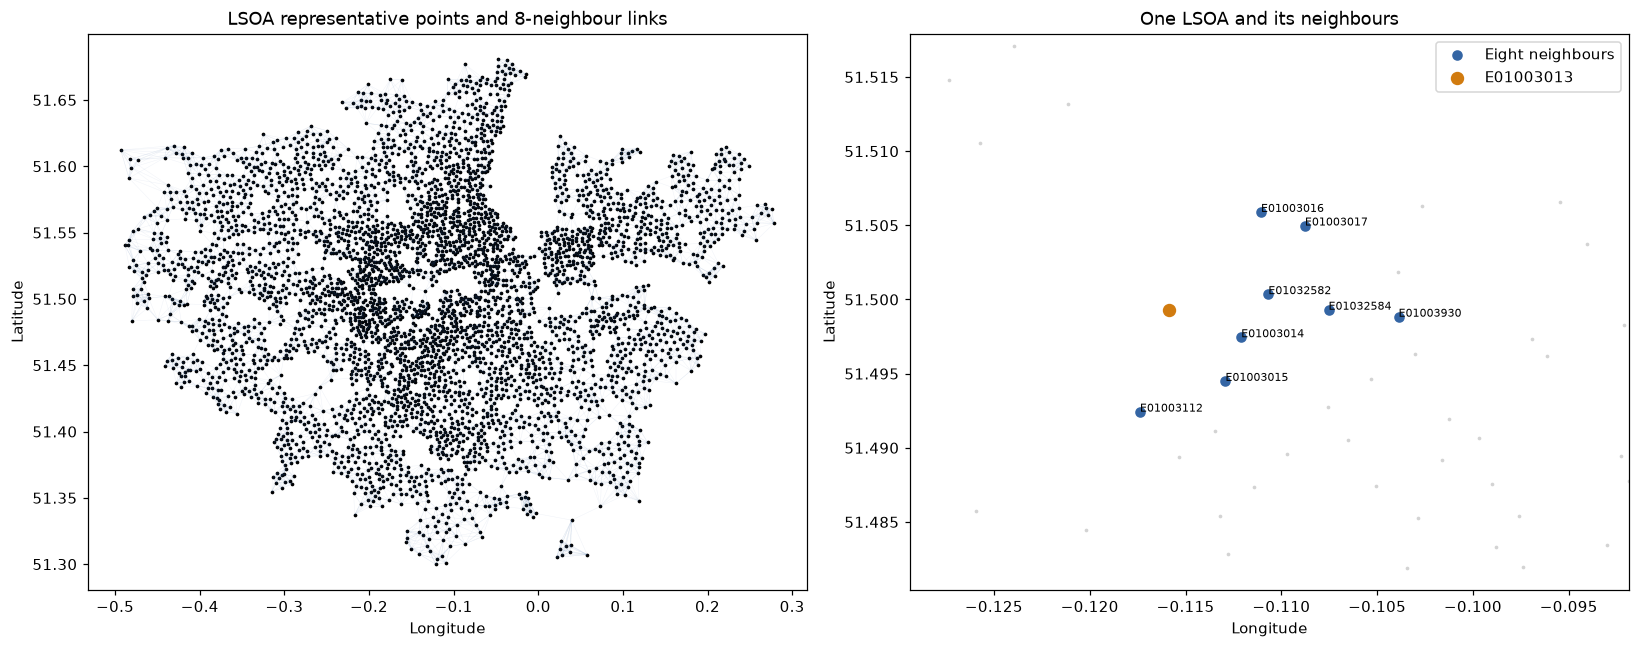

In [7]:
fig,axes=plt.subplots(1,2,figsize=(15,6))
W=weights[8];row,col=W.nonzero()
segments=np.stack([locations[['lon','lat']].to_numpy()[row],locations[['lon','lat']].to_numpy()[col]],axis=1)
axes[0].add_collection(LineCollection(segments,colors='#3465a4',alpha=.07,linewidths=.35))
axes[0].scatter(locations.lon,locations.lat,s=2,color='black');axes[0].autoscale();axes[0].set_title('LSOA representative points and 8-neighbour links')
center=int(np.argmin((locations.lat-51.50)**2+(locations.lon+.12)**2))
ix=neighbours[center,:8]
axes[1].scatter(locations.lon,locations.lat,s=2,color='lightgrey')
axes[1].scatter(locations.iloc[ix].lon,locations.iloc[ix].lat,color='#3465a4',s=35,label='Eight neighbours')
axes[1].scatter(locations.iloc[center].lon,locations.iloc[center].lat,color='#d17b0f',s=60,label=codes[center])
for j in ix:axes[1].annotate(codes[j],(locations.iloc[j].lon,locations.iloc[j].lat),fontsize=7)
pad=.012;axes[1].set_xlim(locations.iloc[np.r_[center,ix]].lon.min()-pad,locations.iloc[np.r_[center,ix]].lon.max()+pad)
axes[1].set_ylim(locations.iloc[np.r_[center,ix]].lat.min()-pad,locations.iloc[np.r_[center,ix]].lat.max()+pad)
axes[1].set_title('One LSOA and its neighbours');axes[1].legend()
for ax in axes:ax.set_xlabel('Longitude');ax.set_ylabel('Latitude')
fig.tight_layout();fig.savefig(OUT/'lsoa_neighbour_map.png',dpi=170);plt.show()


## 2. Global spatial clustering before and after controls

The outcome is the mean log sale price per LSOA-year; price maps use median sale prices. This equal-weight area panel differs from the transaction regressions. Moran I compares each demeaned value with its weighted neighbours. Positive I indicates nearby areas tend to have similar values; it is not a crime-price effect. Permutation p-values use random relabellings, with no multiple-testing correction. Residual permutations are exploratory diagnostics, not exact tests conditional on estimated fixed effects.


In [6]:
def absorb(matrix, groups, tol=1e-10, max_iter=2000):
    z = np.asarray(matrix, dtype=float).copy()
    codes = [pd.factorize(g, sort=False)[0] for g in groups]
    if any(((g < 0).any() for g in codes)):
        raise ValueError('Missing fixed-effect ID')
    for iteration in range(max_iter):
        before = z.copy()
        for g in codes:
            counts = np.bincount(g)
            sums = np.column_stack([np.bincount(g, weights=z[:, j], minlength=len(counts)) for j in range(z.shape[1])])
            z -= (sums / counts[:, None])[g]
        if np.max(np.abs(z - before)) < tol:
            return (z, iteration + 1)
    raise RuntimeError('Fixed-effect absorption did not converge')
def fit_absorbed(data, crime, controls, fixed_effects, cluster='lsoacode'):
    names = ([crime] if crime is not None else []) + controls
    x = data[names].to_numpy(dtype=float, copy=True)
    scale = x.std(axis=0)
    scale[scale < 1e-14] = 1
    x /= scale
    y = data.lnprice.to_numpy(float)
    if fixed_effects:
        z, iterations = absorb(np.column_stack([y, x]), [data[c] for c in fixed_effects])
        y, x = (z[:, 0], z[:, 1:])
    else:
        y = y - y.mean()
        x = x - x.mean(axis=0)
        iterations = 0
    gram = x.T @ x
    keep = []
    for j in range(x.shape[1]):
        residual_norm2 = gram[j, j]
        if keep:
            cross = gram[keep, j]
            residual_norm2 -= cross @ np.linalg.solve(gram[np.ix_(keep, keep)], cross)
        if residual_norm2 > 1e-10 * len(data):
            keep.append(j)
    if crime is not None and 0 not in keep:
        raise ValueError('Crime has no identifying variation in this specification')
    design = x[:, keep]
    beta = np.linalg.lstsq(design, y, rcond=None)[0]
    residual = y - design @ beta
    group = pd.factorize(data[cluster], sort=False)[0]
    G = group.max() + 1
    if G < 2:
        raise ValueError('Need multiple inference clusters')
    scores = np.zeros((G, len(keep)))
    for j in range(len(keep)):
        scores[:, j] = np.bincount(group, weights=design[:, j] * residual, minlength=G)
    bread = np.linalg.inv(design.T @ design)
    covariance = bread @ (scores.T @ scores) @ bread * G / (G - 1)
    estimates = beta / scale[keep]
    se = np.sqrt(np.maximum(np.diag(covariance), 0)) / scale[keep]
    j = keep.index(0)
    critical = stats.t.ppf(0.975, G - 1)
    result = {'N': len(data), 'clusters': G, 'beta': estimates[j], 'se': se[j], 'p': 2 * stats.t.sf(abs(estimates[j] / se[j]), G - 1), 'ci_low': estimates[j] - critical * se[j], 'ci_high': estimates[j] + critical * se[j], 'r2': 1 - residual @ residual / (y @ y), 'r2_type': 'within' if fixed_effects else 'ordinary', 'crime_residual_sd': x[:, 0].std() * scale[0], 'iterations': iterations, 'absorbed_or_collinear': '; '.join((names[j] for j in range(len(names)) if j not in keep)), 'fixed_effects': '; '.join(fixed_effects)}
    coefficients = pd.DataFrame({'variable': [names[j] for j in keep], 'beta': estimates, 'se': se})
    if crime is None:
        for key in ['beta','se','p','ci_low','ci_high','crime_residual_sd']:
            result[key] = np.nan
    return (result, coefficients)


In [9]:
for c in MAIN:area['log1p_'+c]=np.log1p(area[c+'_annual'])
baseline_residuals={}
for category in MAIN:
    columns=['lnprice','log1p_'+category]+CONTROLS
    matrix,_=absorb(area[columns].to_numpy(float),[area.lsoacode,area.year])
    beta=np.linalg.lstsq(matrix[:,1:],matrix[:,0],rcond=None)[0]
    baseline_residuals[category]=matrix[:,0]-matrix[:,1:]@beta
def moran(values,W,permutations=199,seed=SEED):
    z=np.asarray(values,float);z=z-z.mean()
    if z@z<1e-15:return np.nan,np.nan
    factor=len(z)/W.sum();observed=float(factor*(z@(W@z))/(z@z))
    rng=np.random.default_rng(seed);sim=[]
    for _ in range(permutations):
        p=rng.permutation(z);sim.append(float(factor*(p@(W@p))/(p@p)))
    expected=-1/(len(z)-1)
    p=(1+np.sum(np.abs(np.array(sim)-expected)>=abs(observed-expected)))/(permutations+1)
    return observed,float(p)
records=[]
for k,W in weights.items():
    for year in YEARS:
        ix=np.flatnonzero(area.year.eq(year));b=area.iloc[ix]
        assert b.lsoacode.tolist()==list(codes)
        fields={'mean_log_price':b.lnprice.to_numpy(),**{c:b['log1p_'+c].to_numpy() for c in MAIN},**{'residual_'+c:baseline_residuals[c][ix] for c in MAIN}}
        for variable,values in fields.items():
            I,p=moran(values,W,PERMUTATIONS)
            records.append(dict(k=k,year=year,variable=variable,moran_I=I,permutation_p=p,permutations=PERMUTATIONS))
morans=pd.DataFrame(records);table(morans,'moran_diagnostics')


Showing 20 of 84 rows; the complete table is saved as moran_diagnostics.csv.


,k,year,variable,moran_I,permutation_p,permutations
0,4,2012,mean_log_price,0.7465,0.005,199
1,4,2012,mps_all,0.4161,0.005,199
2,4,2012,mps_violence,0.4363,0.005,199
3,4,2012,mps_property,0.3628,0.005,199
4,4,2012,residual_mps_all,0.1412,0.005,199
5,4,2012,residual_mps_violence,0.1409,0.005,199
6,4,2012,residual_mps_property,0.1407,0.005,199
7,4,2013,mean_log_price,0.7565,0.005,199
8,4,2013,mps_all,0.4149,0.005,199
9,4,2013,mps_violence,0.4448,0.005,199


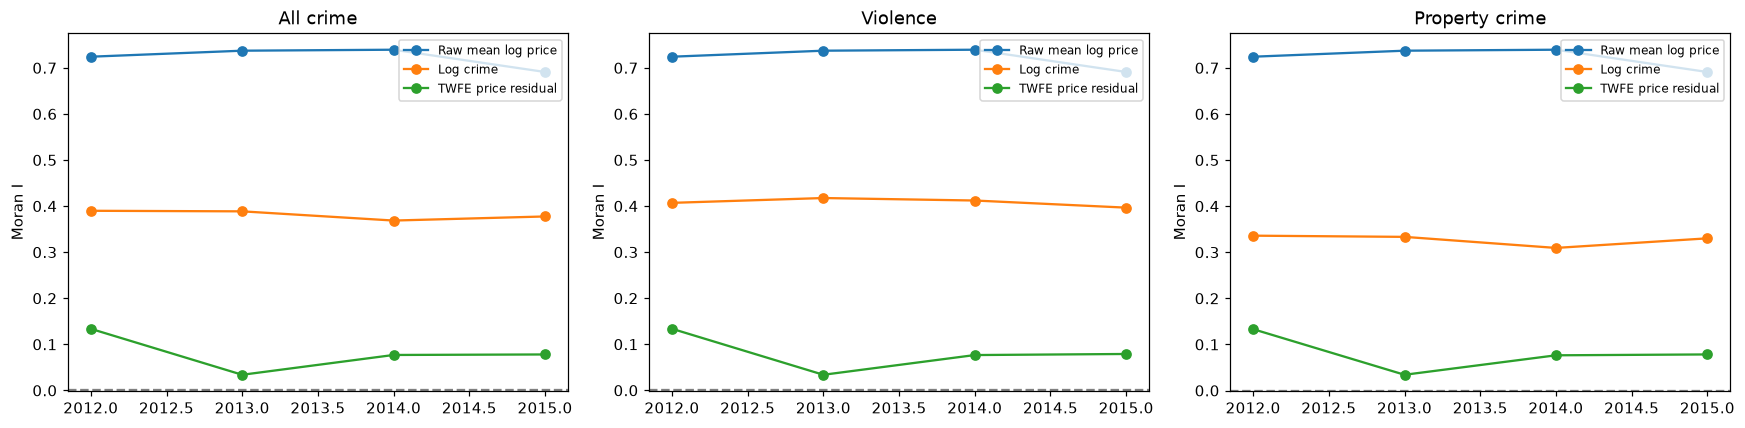

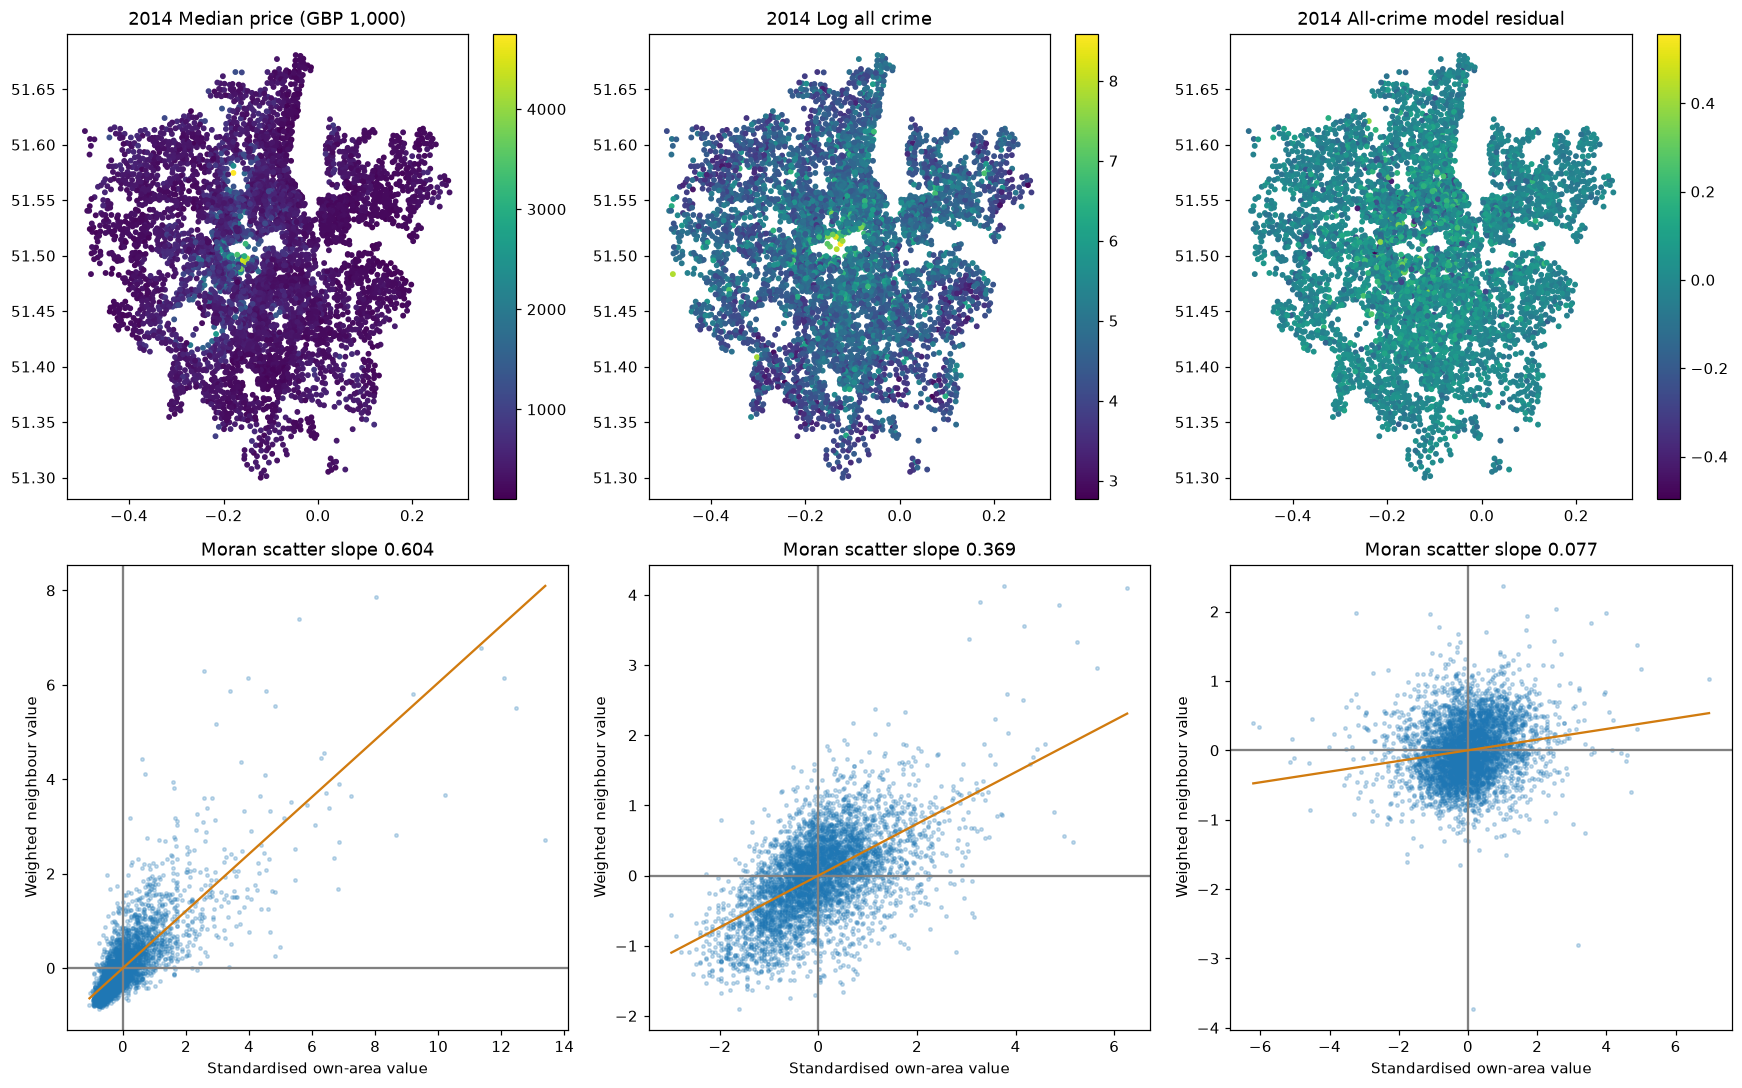

In [10]:
fig,axes=plt.subplots(1,3,figsize=(16,4))
for ax,category in zip(axes,MAIN):
    for variable,label in [('mean_log_price','Raw mean log price'),(category,'Log crime'),('residual_'+category,'TWFE price residual')]:
        b=morans.loc[morans.k.eq(8)&morans.variable.eq(variable)]
        ax.plot(b.year,b.moran_I,marker='o',label=label)
    ax.axhline(0,color='grey',linestyle='--');ax.set_title(CRIME_NAMES[category]);ax.set_ylabel('Moran I');ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(OUT/'moran_by_year.png',dpi=170);plt.show()
year=2014;ix=np.flatnonzero(area.year.eq(year));b=area.iloc[ix]
fig,axes=plt.subplots(2,3,figsize=(16,10))
fields=[('Median price (GBP 1,000)',b.price.to_numpy()/1000),('Log all crime',b.log1p_mps_all.to_numpy()),('All-crime model residual',baseline_residuals['mps_all'][ix])]
for j,(label,values) in enumerate(fields):
    points=axes[0,j].scatter(locations.lon,locations.lat,c=values,s=8,cmap='viridis');fig.colorbar(points,ax=axes[0,j]);axes[0,j].set_title(str(year)+' '+label)
    z=(values-values.mean())/values.std();wz=weights[8]@z
    axes[1,j].scatter(z,wz,s=5,alpha=.25);axes[1,j].axhline(0,color='grey');axes[1,j].axvline(0,color='grey')
    slope=z@wz/(z@z);xx=np.array([z.min(),z.max()]);axes[1,j].plot(xx,slope*xx,color='#d17b0f')
    axes[1,j].set_xlabel('Standardised own-area value');axes[1,j].set_ylabel('Weighted neighbour value');axes[1,j].set_title(f'Moran scatter slope {slope:.3f}')
fig.tight_layout();fig.savefig(OUT/'spatial_maps_and_moran_scatter.png',dpi=170);plt.show()


## 3. Own-area crime versus neighbouring-area crime: SLX experiment

$$\overline{\ln P}_{lt}=\beta C_{lt}+\theta(WC)_{lt}+\gamma'X_{lt}+\psi'(WX^H)_{lt}+\mu_l+\lambda_t+u_{lt}.$$

C is log(1 + annual MPS crime); WC is its distance-weighted neighbour average in the same year. Models compare own crime only, adding WC, adding neighbour property composition, and sensitivity to 4/8/12 neighbours. WX includes property composition, not endogenous neighbour prices. Neighbouring crime can share unobserved shocks with prices, so theta is an adjusted association rather than a causal spillover.

The same balanced LSOA-year sample is used throughout. Standard errors cluster by LSOA and allow temporal dependence, but do not generally allow dependence across LSOAs; residual spatial clustering limits those intervals. A full spatial-HAC or carefully specified spatial-error/IV estimator would be a further extension. SLX is not SAR, and no SAR price multiplier is calculated.


In [11]:
settings=[('Own crime only',8,False,False),('Add neighbour crime',8,True,False),('Add neighbour housing',8,True,True),('Housing + 4 neighbours',4,True,True),('Housing + 12 neighbours',12,True,True)]
rows=[];all_coefficients=[]
for label,k,withcrime,withhousing in settings:
    b=area.copy();W=weights[k]
    for category in MAIN:
        b['W_'+category]=np.concatenate([W@b.loc[b.year.eq(year),'log1p_'+category].to_numpy() for year in YEARS])
    for prop in PROPERTY:b['W_'+prop]=np.concatenate([W@b.loc[b.year.eq(year),prop].to_numpy() for year in YEARS])
    for category in MAIN:
        extra=(['W_'+category] if withcrime else [])+(['W_'+p for p in PROPERTY] if withhousing else [])
        result,coef=fit_absorbed(b,'log1p_'+category,CONTROLS+extra,['lsoacode','year'])
        rows.append(dict(specification=label,k=k,crime=category,**result))
        all_coefficients.append(coef.assign(specification=label,k=k,crime=category))
spatial_results=pd.DataFrame(rows);spatial_coefficients=pd.concat(all_coefficients)
assert len(spatial_results)==15 and spatial_results.N.nunique()==1
table(spatial_results,'spatial_regressions')
spatial_coefficients.to_csv(OUT/'all_spatial_coefficients.csv',index=False)


,specification,k,crime,N,clusters,beta,...,r2,r2_type,crime_residual_sd,iterations,absorbed_or_collinear,fixed_effects
0,Own crime only,8,mps_all,17740,4435,0.0166,...,0.3969,within,0.1356,2,,lsoacode; year
1,Own crime only,8,mps_violence,17740,4435,0.0012,...,0.3964,within,0.2407,2,,lsoacode; year
2,Own crime only,8,mps_property,17740,4435,0.0146,...,0.3969,within,0.1653,2,,lsoacode; year
3,Add neighbour crime,8,mps_all,17740,4435,0.0150,...,0.3969,within,0.1356,2,,lsoacode; year
4,Add neighbour crime,8,mps_violence,17740,4435,0.0014,...,0.3965,within,0.2407,2,,lsoacode; year
5,Add neighbour crime,8,mps_property,17740,4435,0.0128,...,0.3970,within,0.1653,2,,lsoacode; year
6,Add neighbour housing,8,mps_all,17740,4435,0.0148,...,0.3975,within,0.1356,2,,lsoacode; year
7,Add neighbour housing,8,mps_violence,17740,4435,0.0012,...,0.3972,within,0.2407,2,,lsoacode; year
8,Add neighbour housing,8,mps_property,17740,4435,0.0127,...,0.3977,within,0.1653,2,,lsoacode; year
9,Housing + 4 neighbours,4,mps_all,17740,4435,0.0145,...,0.3975,within,0.1356,2,,lsoacode; year


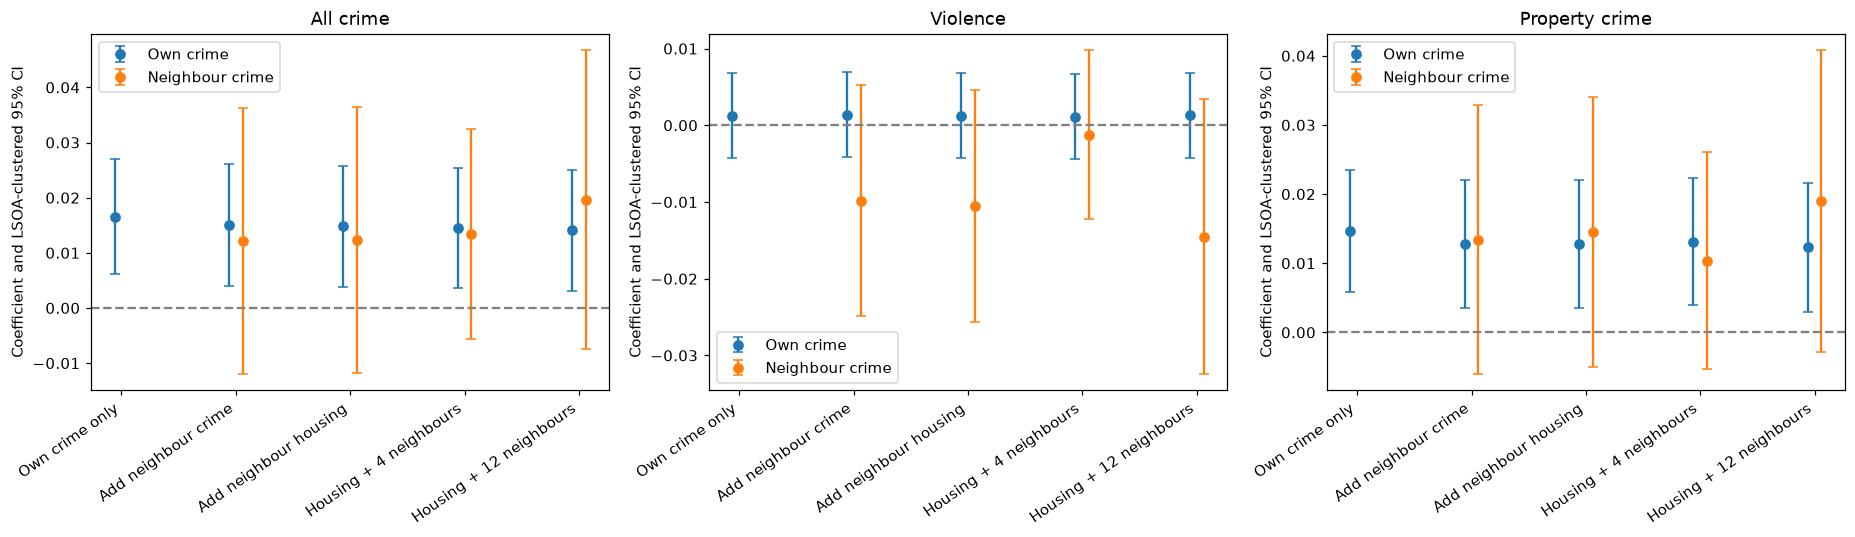

variable,beta,se,ci_low,ci_high
log1p_mps_all,0.01656,0.00533,0.00612,0.02700
detached_dum,0.57976,0.03772,0.50582,0.65371
semi_d_dum,0.29353,0.03472,0.22547,0.36160
terrace_dum,0.19242,0.03357,0.12662,0.25823
freehold,0.38899,0.03352,0.32328,0.45471
newbuild,0.21784,0.01383,0.19072,0.24496
tube_distnear_km,-0.00181,0.02460,-0.05003,0.04642
bus_distnear_km,0.13315,0.04663,0.04173,0.22456
thamesriv_dist_km,-0.02669,0.02432,-0.07438,0.02100
grossannualpay_k,-0.00631,0.00091,-0.00809,-0.00453


In [12]:
fig,axes=plt.subplots(1,3,figsize=(17,5))
labels=[s[0] for s in settings]
for ax,category in zip(axes,MAIN):
    own=spatial_results.loc[spatial_results.crime.eq(category)].set_index('specification').reindex(labels)
    ax.errorbar(np.arange(5)-.06,own.beta,yerr=np.vstack([own.beta-own.ci_low,own.ci_high-own.beta]),fmt='o',capsize=3,label='Own crime')
    neigh=spatial_coefficients.loc[spatial_coefficients.crime.eq(category)&spatial_coefficients.variable.eq('W_'+category)].set_index('specification').reindex(labels)
    critical=stats.t.ppf(.975,len(codes)-1)
    ax.errorbar(np.arange(5)+.06,neigh.beta,yerr=critical*neigh.se,fmt='o',capsize=3,label='Neighbour crime')
    ax.axhline(0,color='grey',linestyle='--');ax.set_xticks(np.arange(5),labels,rotation=35,ha='right')
    ax.set_title(CRIME_NAMES[category]);ax.set_ylabel('Coefficient and LSOA-clustered 95% CI');ax.legend()
fig.tight_layout();fig.savefig(OUT/'own_vs_neighbour_crime.png',dpi=170,bbox_inches='tight');plt.show()
from IPython.display import HTML
cards=[]
for (label,category),b in spatial_coefficients.groupby(['specification','crime'],sort=False):
    c=b[['variable','beta','se']].copy();c['ci_low']=c.beta-critical*c.se;c['ci_high']=c.beta+critical*c.se
    cards.append('<details style="margin:10px;padding:8px;border:1px solid #bbb"><summary>'+label+' / '+CRIME_NAMES[category]+'</summary>'+c.to_html(index=False,float_format=lambda x:f'{x:.5f}')+'</details>')
display(HTML(''.join(cards)))
area.to_csv(OUT/'balanced_lsoa_year_panel.csv.gz',index=False,compression='gzip')


## 4. Interpretation and next steps

Spatial clustering is not proof that crime causes prices, nor that neighbour prices should be included as an ordinary control. Moran statistics describe geographical dependence; SLX estimates conditional own/nearby-crime associations. Compare signs and intervals across neighbour definitions without selecting a graph to obtain a preferred sign. Clustering at LSOA does not solve cross-area residual dependence.

The coordinates are sale-location averages and do not identify adjacency or actual incident distances. Population-weighted LSOA centroids/polygons, neighbouring non-London areas and a pre-specified spatial-HAC or valid spatial-price IV design would improve this experiment. The graph and panel are saved so those upgrades do not require rebuilding the transaction audit.


## 5. Findings from the saved run

The balanced panel includes 4,435 LSOAs observed in all four years (17,740 LSOA-years). With eight-neighbour weights, mean yearly Moran I is about 0.723 for mean log prices, 0.381 for all crime, and 0.081 for all-crime-model residuals. Residual Moran I remains positive in every year. These descriptive statistics indicate that the area/time controls do not exhaust spatial dependence; residual permutation tests are diagnostic rather than exact post-estimation tests.

In the own-crime-only area/year FE model, all-crime beta is +0.01656. Adding eight-neighbour crime and property composition gives +0.01483. Violence is close to zero (+0.00123) in that latter model. The notebook reports all three crime categories and all neighbour definitions, rather than selecting a negative result.

These are equal-weight LSOA-year regressions, unlike the transaction-level notebooks. Aggregation, the balanced panel and annual timing change the estimand. LSOA clustering allows dependence over time within areas, but the observed cross-area residual correlation means its reported intervals may still overstate precision. The SLX model does not solve crime endogeneity or estimate a simultaneous price-spillover multiplier.


## 6. Nearby sales in the previous 24 months: a closer paper-inspired experiment

The paper's neighbouring-sales construction uses 2,000 feet and the previous 24 months with inverse-squared-distance weights. Here we build a row-normalised weighted mean of **log prices** for earlier nearby transactions, with a 25-metre distance floor to prevent identical postcode/building coordinates receiving infinite weight. This is a transparent adaptation, not the paper's exact spatial-IV estimator.

Use at most 6,000 reproducibly selected eligible sales and earlier sales from the full geographically matched source. No same-day or future transaction is used; at least five prior comparable sales are required. Transactions in the same building or previous sales of the same property cannot be reliably identified without full addresses. Completion dates may also differ from the date buyers learned the agreed comparable price.

Compare borough + quarter models with and without this lagged-neighbour-price covariate on identical sales. It is a predictive/conditional control experiment, **not a valid instrument or causal spatial-price coefficient**. Persistent local price shocks, property mix and crime endogeneity remain. Price autocorrelation does not show that neighbours cause each other's prices. These transaction models use prior12 crime and differ from the preceding annual equal-weight LSOA panel.


In [7]:
from scipy.spatial import cKDTree
MAX_COMPARABLE_TARGETS=6000
RADIUS_KM=.6096
DISTANCE_FLOOR_KM=.025
reference=data.loc[data.analysis_geography_ok & data.mps_geography_ok & data.price.gt(0) & data.lat.notna() & data.lon.notna()].copy()
reference['sale_date']=pd.to_datetime(reference.transactiondates)
reference=reference.sort_values('transaction_id').reset_index(drop=True)
ref_lat=np.deg2rad(reference.lat.to_numpy());ref_lon=np.deg2rad(reference.lon.to_numpy())
ref_xyz=np.column_stack([np.cos(ref_lat)*np.cos(ref_lon),np.cos(ref_lat)*np.sin(ref_lon),np.sin(ref_lat)])
ref_tree=cKDTree(ref_xyz)
ref_dates=reference.sale_date.to_numpy(dtype='datetime64[ns]')
ref_logprice=np.log(reference.price.to_numpy())
targets=eligible.sample(n=min(MAX_COMPARABLE_TARGETS,len(eligible)),random_state=SEED).copy()
targets['sale_date']=pd.to_datetime(targets.transactiondates)
chord_radius=2*np.sin(RADIUS_KM/(2*6371))
records=[]
for row in targets.itertuples():
    lat,lon=np.deg2rad([row.lat,row.lon])
    point=np.array([np.cos(lat)*np.cos(lon),np.cos(lat)*np.sin(lon),np.sin(lat)])
    idx=np.array(ref_tree.query_ball_point(point,chord_radius),dtype=int)
    end=np.datetime64(row.sale_date.to_datetime64())
    start=np.datetime64((row.sale_date-pd.DateOffset(months=24)).to_datetime64())
    idx=idx[(ref_dates[idx]>=start)&(ref_dates[idx]<end)]
    if len(idx)<5:
        records.append(dict(transaction_id=row.transaction_id,prior_comparable_count=len(idx),prior_neighbour_logprice=np.nan,mean_neighbour_distance_km=np.nan))
        continue
    distance=2*6371*np.arcsin(np.clip(np.linalg.norm(ref_xyz[idx]-point,axis=1)/2,0,1))
    weight=1/np.maximum(distance,DISTANCE_FLOOR_KM)**2;weight/=weight.sum()
    records.append(dict(transaction_id=row.transaction_id,prior_comparable_count=len(idx),prior_neighbour_logprice=float(weight@ref_logprice[idx]),mean_neighbour_distance_km=float(weight@distance)))
comparables=targets.merge(pd.DataFrame(records),on='transaction_id',validate='one_to_one')
comparables=comparables.loc[comparables.prior_neighbour_logprice.notna()].copy()
comparables[['transaction_id','prior_comparable_count','prior_neighbour_logprice','mean_neighbour_distance_km']].to_csv(OUT/'prior24_comparable_prices.csv',index=False)
table(comparables[['prior_comparable_count','mean_neighbour_distance_km']].describe().T,'comparable_sales_coverage')
print('Comparable-price experiment:',len(comparables),'of',len(targets),'target sales retained')
comparable_rows=[];comparable_coefs=[]
for category in MAIN:
    for with_neighbour in [False,True]:
        extra=['prior_neighbour_logprice'] if with_neighbour else []
        r,c=fit_absorbed(comparables,'log1p_'+category,CONTROLS+extra,['oslaua','yearquarter'])
        label='With prior neighbour prices' if with_neighbour else 'Without neighbour prices'
        comparable_rows.append(dict(crime=category,specification=label,**r))
        comparable_coefs.append(c.assign(crime=category,specification=label))
comparable_results=pd.DataFrame(comparable_rows)
comparable_results.to_csv(OUT/'comparable_price_regressions.csv',index=False)
pd.concat(comparable_coefs).to_csv(OUT/'comparable_price_all_coefficients.csv',index=False)
table(comparable_results[['crime','specification','N','beta','ci_low','ci_high','p']],'comparable_price_regressions')


Comparable-price experiment: 5993 of 6000 target sales retained


,count,mean,std,min,25%,50%,75%,max
prior_comparable_count,5993.0,258.317,159.0265,6.0000,136.0000,216.0000,352.000,929.0000
mean_neighbour_distance_km,5993.0,0.105,0.0629,0.0003,0.0607,0.0909,0.133,0.4374


,crime,specification,N,beta,ci_low,ci_high,p
0,mps_all,Without neighbour prices,5993,-0.0317,-0.0603,-0.0030,3.0114e-02
1,mps_all,With prior neighbour prices,5993,0.0234,0.0053,0.0415,1.1314e-02
2,mps_violence,Without neighbour prices,5993,-0.1499,-0.1730,-0.1267,5.0255e-36
3,mps_violence,With prior neighbour prices,5993,-0.0068,-0.0224,0.0087,3.8972e-01
4,mps_property,Without neighbour prices,5993,0.0369,0.0106,0.0632,6.0418e-03
5,mps_property,With prior neighbour prices,5993,0.0342,0.0170,0.0514,9.8318e-05


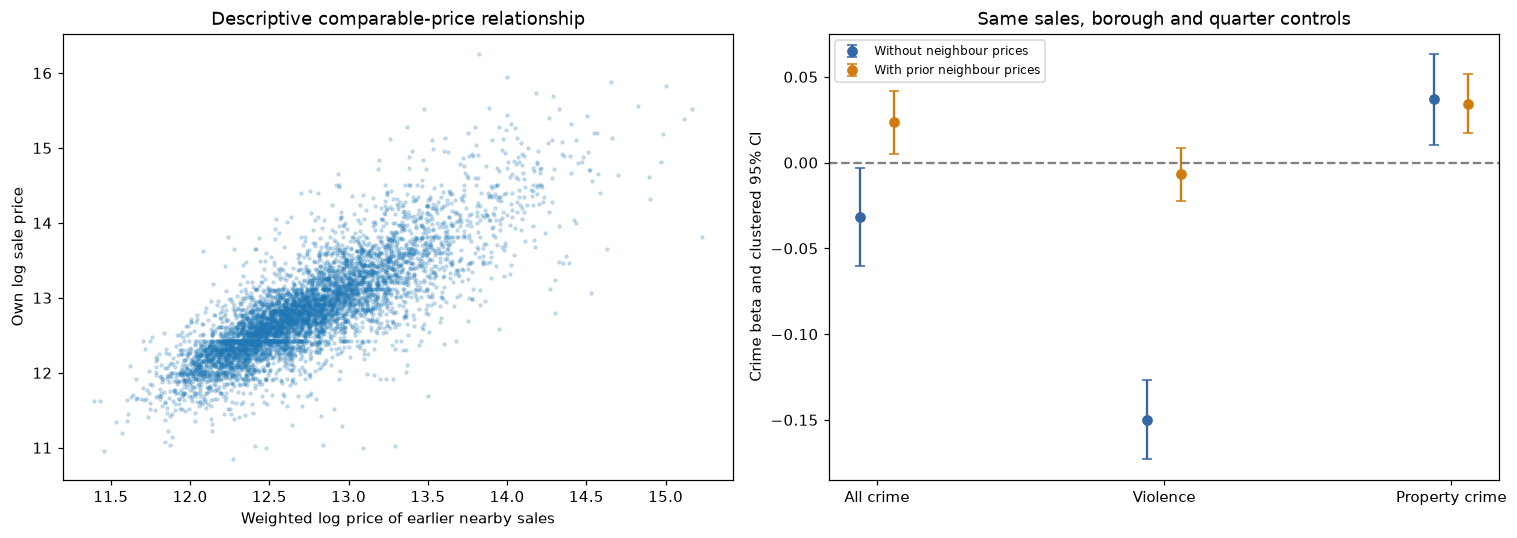

variable,beta,se
log1p_mps_all,-0.03165,0.01459
detached_dum,0.79803,0.06928
semi_d_dum,0.35820,0.06338
terrace_dum,0.16555,0.06193
freehold,0.36006,0.06124
newbuild,0.16009,0.02803
tube_distnear_km,-0.03906,0.00553
bus_distnear_km,0.35107,0.06274
thamesriv_dist_km,-0.02464,0.00466
grossannualpay_k,-0.00457,0.00706


In [8]:
fig,axes=plt.subplots(1,2,figsize=(14,5))
axes[0].scatter(comparables.prior_neighbour_logprice,comparables.lnprice,s=4,alpha=.2)
axes[0].set_xlabel('Weighted log price of earlier nearby sales');axes[0].set_ylabel('Own log sale price')
axes[0].set_title('Descriptive comparable-price relationship')
for with_neighbour,offset,color in [(False,-.06,'#3465a4'),(True,.06,'#d17b0f')]:
    label='With prior neighbour prices' if with_neighbour else 'Without neighbour prices'
    b=comparable_results.loc[comparable_results.specification.eq(label)].set_index('crime').reindex(MAIN)
    axes[1].errorbar(np.arange(3)+offset,b.beta,yerr=np.vstack([b.beta-b.ci_low,b.ci_high-b.beta]),fmt='o',capsize=3,label=label,color=color)
axes[1].axhline(0,color='grey',linestyle='--');axes[1].set_xticks(np.arange(3),[CRIME_NAMES[c] for c in MAIN])
axes[1].set_ylabel('Crime beta and clustered 95% CI');axes[1].legend(fontsize=8)
axes[1].set_title('Same sales, borough and quarter controls')
fig.tight_layout();fig.savefig(OUT/'prior_comparable_price_experiment.png',dpi=170);plt.show()
from IPython.display import HTML
cards=[]
for (crime,spec),b in pd.concat(comparable_coefs).groupby(['crime','specification'],sort=False):
    cards.append('<details style="margin:8px;padding:8px;border:1px solid #bbb"><summary>'+CRIME_NAMES[crime]+' / '+spec+'</summary>'+b[['variable','beta','se']].to_html(index=False,float_format=lambda v:f'{v:.5f}')+'</details>')
display(HTML(''.join(cards)))


## 7. Findings from the comparable-sales experiment

Of 6,000 reproducibly sampled target sales, 5,993 have at least five earlier nearby comparables. In the borough/quarter transaction models, adding the prior-neighbour-price control changes all-crime beta from -0.03165 to +0.02340, and violence from -0.14987 to -0.00683. Property crime remains positive (+0.03688 without and +0.03419 with the control).

This demonstrates substantial sensitivity to spatial price information. It does not show that the new crime coefficients are causal or that neighbours cause prices. Earlier nearby prices can reflect persistent unobserved amenities and earlier crime capitalisation; controlling for them changes the conditioning set and may absorb some of the relationship of interest. The prior-price variable is not treated as a valid excluded instrument, and this is not the paper's spatial-IV quantile estimator. Both versions are retained.
